<a href="https://colab.research.google.com/github/minhimmaturity/ai-engineer/blob/master/02_duong_cong_va_qua_khop.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 📈 Bài 2: Đọc đường cong huấn luyện và học quá khớp

**Buổi 3: Máy học hoạt động như thế nào?** · ⏱️ 25 phút

Sau bài này bạn sẽ:
- Đọc được đường cong train và validation
- Phân biệt **học chưa đủ**, **khớp tốt** và **học quá khớp** (slide 45)
- Dùng **Dừng sớm** và **Dropout** để giảm quá khớp (slide 47–51)

**Hình ảnh cần nhớ:** train giống **bài tập về nhà**, validation giống **đề thi thử chưa từng thấy**. Làm bài tập ngày càng giỏi nhưng thi thử ngày càng tệ là dấu hiệu của **học vẹt**.

Chạy ô cài đặt bên dưới trước (`Shift + Enter`). Chỗ cần điền là dấu `____`.

In [1]:
#@title ⚙️ Ô cài đặt: bấm ▶ để chạy, không cần đọc code { display-mode: "form" }

import os, time, unicodedata, warnings
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from matplotlib.animation import FuncAnimation
from matplotlib.colors import LinearSegmentedColormap
from IPython.display import HTML, display
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split

MAU_TRAIN, MAU_VAL, MAU_3 = "#2a78d6", "#eb6834", "#1baf7a"
MAU_LOP0, MAU_LOP1 = "#e34948", "#2a78d6"
MUC_CHINH, MUC_PHU = "#0b0b0b", "#52514e"
NEN_HAI_LOP = LinearSegmentedColormap.from_list("nen", ["#f3b4b3", "#f0efec", "#a9c9f0"])

plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7", "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False, "axes.axisbelow": True,
    "text.color": MUC_CHINH, "axes.labelcolor": MUC_PHU, "axes.titlecolor": MUC_CHINH,
    "xtick.color": MUC_PHU, "ytick.color": MUC_PHU, "lines.linewidth": 2, "font.size": 11,
    "axes.titlesize": 12, "legend.frameon": False, "figure.dpi": 100, "animation.embed_limit": 40,
})


def _bao_loi_than_thien(self, etype, value, tb, tb_offset=None):
    ten = getattr(value, "name", None) or str(value)
    if "____" in str(value):
        print("✏️  Ô này còn chỗ trống ____ chưa điền.\n"
              "    Hãy thay MỌI dấu ____ trong ô bằng giá trị theo gợi ý, rồi chạy lại ô.")
    else:
        print(f"🔎 Python chưa biết tên `{ten}`. Thường là do một trong ba lý do:\n"
              "    1. Một ô phía trên chưa chạy hoặc còn lỗi: hãy chạy lại các ô từ trên xuống.\n"
              "    2. Gõ sai tên (hoa/thường cũng tính là khác nhau).\n"
              '    3. Quên dấu ngoặc kép với chữ, ví dụ phải viết "relu" chứ không phải relu.')


try:
    get_ipython().set_custom_exc((NameError,), _bao_loi_than_thien)
except Exception:
    pass


def _dung(thong_bao):
    print("✅ " + thong_bao)


def _sai(thong_bao):
    print("❌ " + thong_bao)


def _luoi(X, n=90):
    bien_x = (X[:, 0].max() - X[:, 0].min()) * 0.12
    bien_y = (X[:, 1].max() - X[:, 1].min()) * 0.12
    xx, yy = np.meshgrid(np.linspace(X[:, 0].min() - bien_x, X[:, 0].max() + bien_x, n),
                         np.linspace(X[:, 1].min() - bien_y, X[:, 1].max() + bien_y, n))
    return xx, yy, np.c_[xx.ravel(), yy.ravel()].astype("float32")


def _xac_suat(model, luoi, hinh_dang):
    return np.array(model(luoi, training=False)).reshape(hinh_dang)


def _ve_nen(ax, xx, yy, zz):
    ax.contourf(xx, yy, zz, levels=np.linspace(0, 1, 41), cmap=NEN_HAI_LOP, vmin=0, vmax=1)
    if zz.min() < 0.5 < zz.max():
        ax.contour(xx, yy, zz, levels=[0.5], colors=MUC_CHINH, linewidths=2)


def _ve_diem(ax, X, y, nhan, rong=False):
    for lop, mau, dau in [(0, MAU_LOP0, "s"), (1, MAU_LOP1, "o")]:
        loc = np.asarray(y) == lop
        ten = f"{nhan[lop]}" + (" (validation)" if rong else "")
        if rong:
            ax.scatter(X[loc, 0], X[loc, 1], s=46, marker=dau, facecolors="#fcfcfb",
                       edgecolors=mau, linewidths=1.6, label=ten, zorder=3)
        else:
            ax.scatter(X[loc, 0], X[loc, 1], s=46, marker=dau, c=mau,
                       edgecolors="#fcfcfb", linewidths=0.8, label=ten, zorder=3)


class GhiLaiRanhGioi(tf.keras.callbacks.Callback):
    """Chụp lại đường phân chia của mô hình sau mỗi vài epoch."""

    def __init__(self, X, moi_bao_nhieu_epoch=2):
        super().__init__()
        self.moi = moi_bao_nhieu_epoch
        self.xx, self.yy, self.luoi = _luoi(X)
        self.cac_epoch, self.cac_khung = [], []

    def _chup(self, epoch):
        self.cac_epoch.append(epoch)
        self.cac_khung.append(_xac_suat(self.model, self.luoi, self.xx.shape))

    def on_train_begin(self, logs=None):
        self._chup(0)

    def on_epoch_end(self, epoch, logs=None):
        if (epoch + 1) % self.moi == 0:
            self._chup(epoch + 1)


def xem_qua_trinh_hoc(ghi_lai, lich_su, X_train, y_train, nhan=("Lớp 0", "Lớp 1"),
                      truc=("x1", "x2"), X_val=None, y_val=None):
    """Hoạt ảnh: bên trái là đường phân chia, bên phải là đường cong loss."""
    train, val = lich_su.history["loss"], lich_su.history["val_loss"]
    so_epoch = np.arange(1, len(train) + 1)
    fig, (ax_trai, ax_phai) = plt.subplots(1, 2, figsize=(10.5, 4.3), dpi=80)
    ax_phai.set_xlim(0, len(train))
    ax_phai.set_ylim(0, max(max(train), max(val)) * 1.08)
    ax_phai.set_xlabel("Epoch (số lần học hết dữ liệu)")
    ax_phai.set_ylabel("Hàm mất mát (loss)")
    duong_train, = ax_phai.plot([], [], color=MAU_TRAIN, label="Train (bài tập)")
    duong_val, = ax_phai.plot([], [], color=MAU_VAL, label="Validation (thi thử)")
    con_tro = ax_phai.axvline(0, color=MUC_PHU, linestyle="--", linewidth=1)
    ax_phai.legend(loc="upper right")
    ax_phai.set_title("Sai số theo thời gian")

    def ve_khung(i):
        epoch = ghi_lai.cac_epoch[i]
        ax_trai.clear()
        _ve_nen(ax_trai, ghi_lai.xx, ghi_lai.yy, ghi_lai.cac_khung[i])
        _ve_diem(ax_trai, X_train, y_train, nhan)
        if X_val is not None:
            _ve_diem(ax_trai, X_val, y_val, nhan, rong=True)
        ax_trai.set_xlim(ghi_lai.xx.min(), ghi_lai.xx.max())
        ax_trai.set_ylim(ghi_lai.yy.min(), ghi_lai.yy.max())
        ax_trai.set_xlabel(truc[0])
        ax_trai.set_ylabel(truc[1])
        ax_trai.grid(False)
        ax_trai.set_title(f"Đường phân chia sau epoch {epoch}")
        ax_trai.legend(loc="best", fontsize=8, frameon=True, framealpha=0.85, edgecolor="none")
        duong_train.set_data(so_epoch[:epoch], train[:epoch])
        duong_val.set_data(so_epoch[:epoch], val[:epoch])
        con_tro.set_xdata([epoch, epoch])

    ve_khung(0)
    fig.tight_layout()
    hoat_anh = FuncAnimation(fig, ve_khung, frames=len(ghi_lai.cac_khung), interval=180)
    html = hoat_anh.to_jshtml(default_mode="once")
    plt.close(fig)
    return HTML(html)


def ve_duong_cong(lich_su, tieu_de=""):
    """Vẽ 2 biểu đồ: loss và accuracy của train + validation."""
    fig, cac_truc = plt.subplots(1, 2, figsize=(10.5, 3.8))
    for ax, khoa, nhan_y in zip(cac_truc, ["loss", "accuracy"], ["Hàm mất mát (loss)", "Độ chính xác (accuracy)"]):
        for ten, tien_to, mau in [("Train", "", MAU_TRAIN), ("Validation", "val_", MAU_VAL)]:
            du_lieu = lich_su.history[tien_to + khoa]
            ax.plot(range(1, len(du_lieu) + 1), du_lieu, color=mau, label=ten)
        ax.set_xlabel("Epoch")
        ax.set_ylabel(nhan_y)
        ax.legend()
    if tieu_de:
        fig.suptitle(tieu_de)
    fig.tight_layout()
    plt.show()



def lay_du_lieu():
    """Cố tình ít dữ liệu và nhiều nhiễu để quá khớp hiện rõ."""
    X, y = make_moons(n_samples=100, noise=0.3, random_state=42)
    return train_test_split(X, y, test_size=0.5, random_state=42)


def ve_hai_tap(X_train, y_train, X_val, y_val):
    fig, ax = plt.subplots(figsize=(6.4, 4.4))
    _ve_diem(ax, X_train, y_train, ("Lớp 0", "Lớp 1"))
    _ve_diem(ax, X_val, y_val, ("Lớp 0", "Lớp 1"), rong=True)
    ax.set_xlabel("x1")
    ax.set_ylabel("x2")
    ax.set_title("Điểm đặc: train · Điểm rỗng: validation")
    ax.legend(loc="upper left", bbox_to_anchor=(1, 1))
    fig.tight_layout()
    plt.show()


def xem_ca_ba_benh_nhan():
    """Đường cong minh họa, được dựng bằng công thức để thấy rõ từng dạng."""
    rng = np.random.default_rng(42)
    t = np.arange(1, 61)
    nhieu = lambda: rng.normal(0, 0.006, 60)
    A = (0.70 * np.exp(-t / 8) + 0.02 + nhieu(), 0.70 * np.exp(-t / 8) + 0.25 + 0.012 * np.maximum(0, t - 15) + nhieu())
    B = (0.68 - 0.05 * (1 - np.exp(-t / 15)) + nhieu(), 0.70 - 0.05 * (1 - np.exp(-t / 15)) + nhieu())
    C = (0.70 * np.exp(-t / 10) + 0.12 + nhieu(), 0.70 * np.exp(-t / 10) + 0.17 + nhieu())
    fig, cac_truc = plt.subplots(1, 3, figsize=(12, 3.6), sharey=True)
    for ax, (train, val), ten in zip(cac_truc, [A, B, C], ["Bệnh nhân A", "Bệnh nhân B", "Bệnh nhân C"]):
        ax.plot(t, train, color=MAU_TRAIN, label="Train")
        ax.plot(t, val, color=MAU_VAL, label="Validation")
        ax.set_title(ten)
        ax.set_xlabel("Epoch")
        ax.legend()
    cac_truc[0].set_ylabel("Loss")
    fig.tight_layout()
    plt.show()


def _chuan_hoa(chu):
    chu = str(chu).lower().replace("đ", "d")
    chu = "".join(k for k in unicodedata.normalize("NFD", chu) if unicodedata.category(k) != "Mn")
    return " ".join(chu.replace("_", " ").split())


def cham_chan_doan(A, B, C):
    dap_an = {
        "A": ("qua khop", "train tiếp tục giảm nhưng validation đi lên: học vẹt."),
        "B": ("hoc chua du", "cả hai đường đều cao và gần như không giảm: mô hình chưa nắm được quy luật."),
        "C": ("khop tot", "cả hai đường cùng giảm, nằm sát nhau và không đi lên."),
    }
    for ten, tra_loi in {"A": A, "B": B, "C": C}.items():
        dung, ly_do = dap_an[ten]
        if _chuan_hoa(tra_loi) == dung:
            _dung(f"Bệnh nhân {ten}: chính xác, {ly_do}")
        else:
            _sai(f'Bệnh nhân {ten}: chưa đúng. Hãy nhìn khoảng cách giữa hai đường và xem đường validation có đi lên không. Chọn "hoc chua du", "khop tot" hoặc "qua khop".')


def kiem_tra_duong_cong(train, val, lich_su):
    if train is lich_su.history["loss"] or list(train) == list(lich_su.history["loss"]):
        if list(val) == list(lich_su.history["val_loss"]):
            _dung("Lấy đúng dữ liệu cho cả hai đường!")
            return
    _sai('Hãy lấy lich_su.history["loss"] cho train và lich_su.history["val_loss"] cho validation.')


def kiem_tra_epoch_tot_nhat(epoch_tot_nhat, lich_su):
    dung = int(np.argmin(lich_su.history["val_loss"])) + 1
    if epoch_tot_nhat == dung:
        _dung(f"Đúng! Val loss thấp nhất tại epoch {dung} ({lich_su.history['val_loss'][dung - 1]:.2f}), sau đó mô hình bắt đầu học vẹt.")
    elif epoch_tot_nhat == dung - 1:
        _sai("Gần đúng rồi! np.argmin đếm từ 0 còn epoch đếm từ 1, nên cần cộng thêm 1.")
    else:
        _sai('Hãy tìm vị trí nhỏ nhất của lich_su.history["val_loss"] rồi cộng thêm 1.')


def ve_diem_dung(lich_su, epoch):
    train, val = lich_su.history["loss"], lich_su.history["val_loss"]
    fig, ax = plt.subplots(figsize=(8, 4))
    ax.plot(range(1, len(train) + 1), train, color=MAU_TRAIN, label="Train")
    ax.plot(range(1, len(val) + 1), val, color=MAU_VAL, label="Validation")
    ax.axvline(epoch, color=MUC_PHU, linestyle="--", linewidth=1)
    ax.scatter([epoch], [val[epoch - 1]], s=70, c=MAU_VAL, edgecolors="#fcfcfb", linewidths=2, zorder=4)
    ax.annotate(f"Nên dừng ở đây (epoch {epoch})", (epoch, val[epoch - 1]),
                xytext=(epoch + len(val) * 0.06, max(val) * 0.75), color=MUC_CHINH,
                arrowprops=dict(arrowstyle="->", color=MUC_PHU))
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Loss")
    ax.set_title("Giống slide 51: trước điểm dừng còn tiến bộ, sau đó là học quá khớp")
    ax.legend(loc="center right")
    fig.tight_layout()
    plt.show()


def kiem_tra_dung_som(dung_som, lich_su):
    if dung_som.monitor != "val_loss":
        _sai('EarlyStopping cần theo dõi monitor="val_loss", vì đó là điểm thi thử.')
    elif dung_som.patience != 20:
        _sai("Bài này dùng patience=20: chờ thêm 20 epoch không tiến bộ thì dừng.")
    elif len(lich_su.history["loss"]) >= 200:
        _sai("Mô hình vẫn chạy đủ 200 epoch. Bạn đã đưa dung_som vào callbacks chưa?")
    else:
        _dung(f"Mô hình tự dừng sau {len(lich_su.history['loss'])} epoch thay vì 200.")


def kiem_tra_dropout(model):
    lop = [l for l in model.layers if isinstance(l, tf.keras.layers.Dropout)]
    if len(lop) == 2 and all(abs(l.rate - 0.5) < 1e-9 for l in lop):
        _dung("Có 2 lớp Dropout, mỗi lớp tắt ngẫu nhiên 50% nơ-ron khi huấn luyện.")
    else:
        _sai("Cần đặt Dropout(rate=0.5) ngay sau mỗi lớp Dense ẩn (tổng cộng 2 lớp Dropout).")


def so_sanh_ba_cach(cac_mo_hinh, X_val, y_val, X_train, y_train):
    """cac_mo_hinh: danh sách (tên, model, lịch sử)."""
    mau = [MAU_TRAIN, MAU_VAL, MAU_3]
    fig, ax = plt.subplots(figsize=(8.4, 3.9))
    bang = []
    for (ten, model, lich_su), m in zip(cac_mo_hinh, mau):
        val = lich_su.history["val_loss"]
        ax.plot(range(1, len(val) + 1), val, color=m, label=ten)
        ax.annotate(ten, (len(val), val[-1]), xytext=(6, -12 if len(val) < 200 else 0), textcoords="offset points",
                    va="center", color=MUC_CHINH, fontsize=10, annotation_clip=False)
        loss, acc = model.evaluate(X_val, y_val, verbose=0)
        bang.append({"Cách làm": ten, "Số epoch đã chạy": len(val), "Val loss": round(loss, 2), "Val accuracy": round(acc, 2)})
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Val loss")
    ax.set_title("Val loss của ba mô hình: thấp hơn là tốt hơn")
    ax.legend(loc="upper left")
    fig.tight_layout()
    plt.show()
    display(pd.DataFrame(bang).set_index("Cách làm"))

    xx, yy, luoi = _luoi(np.vstack([X_train, X_val]))
    fig, cac_truc = plt.subplots(1, 3, figsize=(12, 3.8), sharex=True, sharey=True)
    for ax, (ten, model, _) in zip(cac_truc, cac_mo_hinh):
        _ve_nen(ax, xx, yy, _xac_suat(model, luoi, xx.shape))
        _ve_diem(ax, X_train, y_train, ("Lớp 0", "Lớp 1"))
        _ve_diem(ax, X_val, y_val, ("Lớp 0", "Lớp 1"), rong=True)
        ax.grid(False)
        ax.set_xlim(xx.min(), xx.max())
        ax.set_ylim(yy.min(), yy.max())
        ax.set_title(ten)
        ax.set_xlabel("x1")
    cac_truc[0].set_ylabel("x2")
    cac_truc[-1].legend(loc="upper left", bbox_to_anchor=(1, 1), fontsize=9)
    fig.tight_layout()
    plt.show()


print("✅ Cài đặt xong! TensorFlow phiên bản", tf.__version__)

✅ Cài đặt xong! TensorFlow phiên bản 2.21.0


---
# 🔍 Phần A: Xem mẫu (8 phút)

## A1. Tạo một "học sinh học vẹt"

Để thấy quá khớp thật rõ, ta cố tình tạo điều kiện:
- **Ít dữ liệu, nhiều nhiễu:** chỉ có 50 điểm để học
- **Mô hình rất lớn:** 2 lớp ẩn, mỗi lớp 128 nơ-ron, tức là nhiều "trí nhớ" hơn mức cần thiết
- **Học rất lâu:** 200 epoch

🤔 **Dự đoán:** sau 200 epoch, độ chính xác trên **train** và trên **validation** sẽ như thế nào?

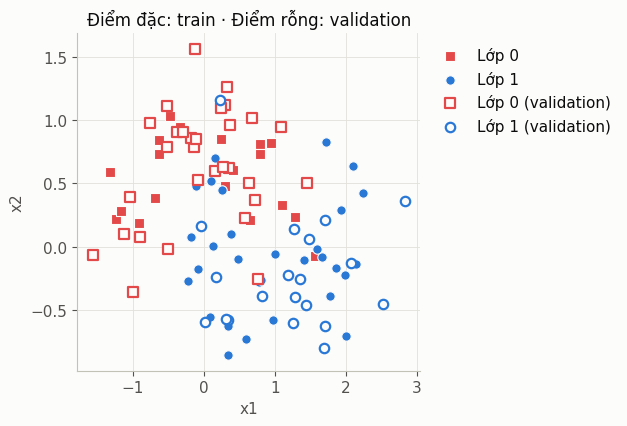

In [3]:
X_train, X_val, y_train, y_val = lay_du_lieu()
ve_hai_tap(X_train, y_train, X_val, y_val)

In [4]:
tf.keras.utils.set_random_seed(42)

mo_hinh_goc = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(2,)),
    tf.keras.layers.Dense(128, activation="relu"),    # 128 nơ-ron: thừa sức "thuộc lòng" 50 điểm
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dense(1, activation="sigmoid"),
])
mo_hinh_goc.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.002),
    loss="binary_crossentropy",
    metrics=["accuracy"],
)

ghi_lai = GhiLaiRanhGioi(np.vstack([X_train, X_val]), moi_bao_nhieu_epoch=5)
lich_su = mo_hinh_goc.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),   # đề thi thử được chấm sau mỗi epoch
    epochs=200,
    batch_size=16,
    verbose=0,
    callbacks=[ghi_lai],
)

print(f"Train accuracy:      {lich_su.history['accuracy'][-1]:.0%}  ← bài tập")
print(f"Validation accuracy: {lich_su.history['val_accuracy'][-1]:.0%}  ← thi thử")

Train accuracy:      98%  ← bài tập
Validation accuracy: 80%  ← thi thử


## A2. 🎬 Nhìn đường cong và mô hình cùng lúc

Kéo thanh trượt thật chậm và quan sát: **khi đường cam (validation) bắt đầu đi lên, đường phân chia bên trái đang làm gì?**

In [5]:
xem_qua_trinh_hoc(ghi_lai, lich_su, X_train, y_train, X_val=X_val, y_val=y_val)

## A3. Cách đọc đường cong

| Hình dạng | Chẩn đoán | Ví von | Hướng xử lý |
|---|---|---|---|
| Cả hai đường **đều cao**, gần như không giảm | **Học chưa đủ** (underfitting) | Chưa học bài | Mô hình lớn hơn, học lâu hơn |
| Cả hai cùng giảm, **nằm sát nhau** | **Khớp tốt** (good fit) | Hiểu bài | Giữ nguyên |
| Train giảm tiếp, **validation đi lên** | **Học quá khớp** (overfitting) | Học vẹt | Dừng sớm, Dropout, thêm dữ liệu |

Lưu ý: các đường có thể hơi răng cưa, ta nhìn **xu hướng chung** chứ không nhìn từng nhịp lên xuống.

## A4. 🩺 Trò chơi: Bác sĩ mô hình (5 phút)

Đây là ba đường cong minh họa. Hãy chẩn đoán từng bệnh nhân bằng một trong ba đáp án: `"hoc chua du"`, `"khop tot"`, `"qua khop"` (gõ có dấu hay không dấu đều được).

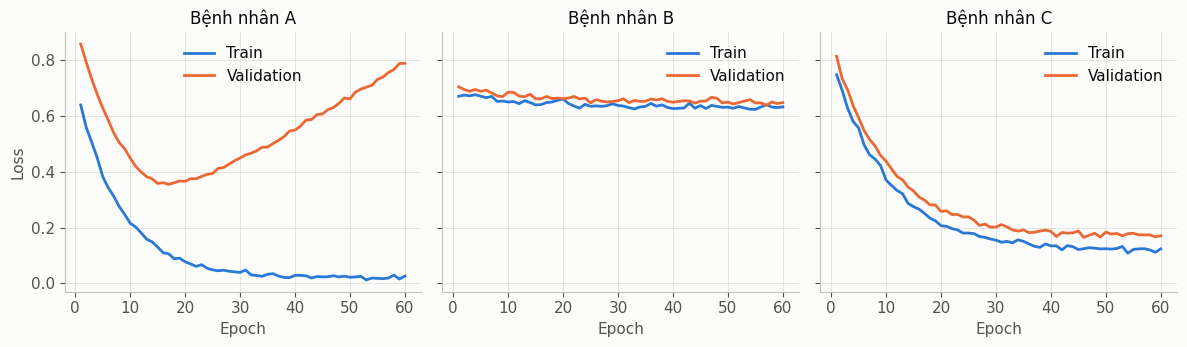

In [ ]:
xem_ca_ba_benh_nhan()

In [ ]:
cham_chan_doan(
    A= "qua khop",      # ✏️ chẩn đoán bệnh nhân A, nhớ để trong dấu ngoặc kép
    B= "hoc chua du",   # ✏️ chẩn đoán bệnh nhân B
    C= "khop tot",      # ✏️ chẩn đoán bệnh nhân C
)

✅ Bệnh nhân A: chính xác, train tiếp tục giảm nhưng validation đi lên: học vẹt.
✅ Bệnh nhân B: chính xác, cả hai đường đều cao và gần như không giảm: mô hình chưa nắm được quy luật.
✅ Bệnh nhân C: chính xác, cả hai đường cùng giảm, nằm sát nhau và không đi lên.


---
# ✏️ Phần B: Bạn tự làm (12 phút)

## B1. ✏️ Tự vẽ đường cong

`lich_su.history` là một **từ điển**: đưa vào tên thì lấy ra danh sách các giá trị theo từng epoch.

| Tên | Ý nghĩa |
|---|---|
| `"loss"` | Sai số trên train |
| `"val_loss"` | Sai số trên validation |
| `"accuracy"` | Độ chính xác trên train |
| `"val_accuracy"` | Độ chính xác trên validation |

`plt.plot(danh_sach, label=..., color=...)` vẽ một đường, `label` là tên hiện trong chú giải.

<details><summary>💡 Bấm để xem gợi ý</summary>

`train_loss = lich_su.history["loss"]`, còn validation thì dùng khóa `"val_loss"`. Ở `plt.plot`, đưa vào đúng biến tương ứng.
</details>

Các khóa có trong history: ['accuracy', 'loss', 'val_accuracy', 'val_loss']


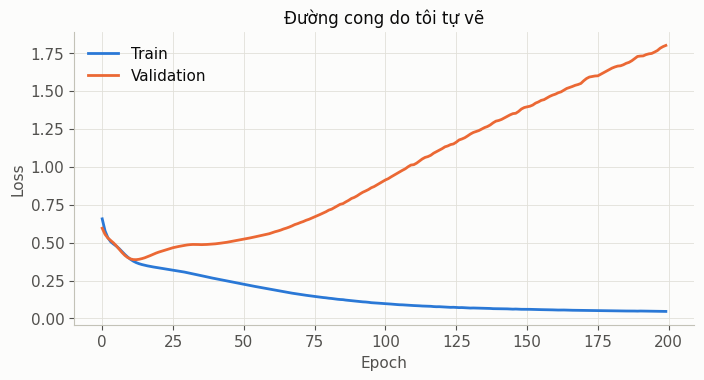

✅ Lấy đúng dữ liệu cho cả hai đường!


In [6]:
print("Các khóa có trong history:", list(lich_su.history.keys()))

train_loss = lich_su.history["loss"]        # ✏️ sai số trên train
val_loss = lich_su.history["val_loss"]      # ✏️ sai số trên validation

plt.figure(figsize=(8, 3.8))
plt.plot(train_loss, label="Train", color=MAU_TRAIN)     # ✏️ vẽ đường train
plt.plot(val_loss, label="Validation", color=MAU_VAL)    # ✏️ vẽ đường validation
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Đường cong do tôi tự vẽ")
plt.legend()
plt.show()

kiem_tra_duong_cong(train_loss, val_loss, lich_su)

## B2. ✏️ Tìm epoch nên dừng

Nên dừng tại epoch có **val loss thấp nhất**. `np.argmin(danh_sach)` trả về **vị trí** của giá trị nhỏ nhất.

⚠️ Python đếm vị trí **từ 0**, còn epoch ta đếm **từ 1**, nên phải cộng thêm 1.

<details><summary>💡 Bấm để xem gợi ý</summary>

`epoch_tot_nhat = int(np.argmin(val_loss)) + 1`
</details>

✅ Đúng! Val loss thấp nhất tại epoch 13 (0.39), sau đó mô hình bắt đầu học vẹt.


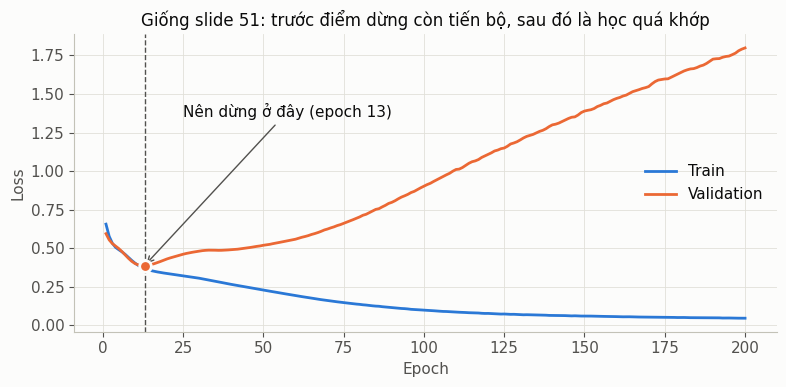

In [7]:
epoch_tot_nhat = int(np.argmin(val_loss)) + 1 # ✏️ danh sách cần tìm và số cần cộng thêm

kiem_tra_epoch_tot_nhat(epoch_tot_nhat, lich_su)
ve_diem_dung(lich_su, epoch_tot_nhat)

## B3. ✏️ Cách chữa 1: Dừng sớm (slide 49–51)

Thay vì tự nhìn biểu đồ, ta nhờ Keras canh hộ bằng `EarlyStopping`:

| Tham số | Ý nghĩa |
|---|---|
| `monitor` | Theo dõi chỉ số nào. Ta theo dõi `"val_loss"` |
| `patience` | Kiên nhẫn: chờ thêm bao nhiêu epoch không tiến bộ thì dừng. Bài này dùng `20` |
| `restore_best_weights=True` | Khi dừng, quay về trọng số tốt nhất đã gặp |

🤔 **Dự đoán:** mô hình sẽ dừng khoảng epoch bao nhiêu? *(Gợi ý: cộng `patience` vào epoch bạn vừa tìm được.)*

In [8]:
tf.keras.utils.set_random_seed(42)

mo_hinh_dung_som = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(2,)),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dense(1, activation="sigmoid"),
])
mo_hinh_dung_som.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.002),
    loss="binary_crossentropy",
    metrics=["accuracy"],
)

dung_som = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",          # ✏️ chỉ số cần theo dõi (phải để trong dấu ngoặc kép)
    patience=20,                 # ✏️ số epoch chờ thêm
    restore_best_weights=True,
)

lich_su_dung_som = mo_hinh_dung_som.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=200,                    # đặt tối đa 200, EarlyStopping sẽ dừng sớm hơn
    batch_size=16,
    verbose=0,
    callbacks=[dung_som],        # ✏️ đưa công cụ dừng sớm vào đây
)

kiem_tra_dung_som(dung_som, lich_su_dung_som)

✅ Mô hình tự dừng sau 33 epoch thay vì 200.


## B4. ✏️ Cách chữa 2: Dropout (slide 47–48)

Khi huấn luyện, Dropout **tắt ngẫu nhiên** một số nơ-ron ở mỗi bước. Giống một đội bóng phải tập khi có người vắng ngẫu nhiên: không ai được dựa dẫm vào riêng một ngôi sao. Lúc dự đoán thì tất cả nơ-ron đều hoạt động.

Hãy thêm `tf.keras.layers.Dropout(rate=0.5)` sau mỗi lớp ẩn. `rate=0.5` nghĩa là tắt 50%.

> ⚠️ **Lưu ý khi đối chiếu slide 48:** trong Keras, tham số tên là `rate`. Viết `Dropout(p=0.5)` sẽ báo lỗi, `p` là cách viết của PyTorch.

In [9]:
tf.keras.utils.set_random_seed(42)

mo_hinh_dropout = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(2,)),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dropout(rate=0.5),             # ✏️ tắt ngẫu nhiên 50%
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dropout(rate=0.5),             # ✏️ tên lớp cần thêm
    tf.keras.layers.Dense(1, activation="sigmoid"),
])
mo_hinh_dropout.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.002),
    loss="binary_crossentropy",
    metrics=["accuracy"],
)

lich_su_dropout = mo_hinh_dropout.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=200,
    batch_size=16,
    verbose=0,
)

kiem_tra_dropout(mo_hinh_dropout)

✅ Có 2 lớp Dropout, mỗi lớp tắt ngẫu nhiên 50% nơ-ron khi huấn luyện.


## B5. So sánh ba mô hình

Chạy ô dưới đây. Bảng đo trên validation bằng trọng số mà mỗi mô hình giữ lại sau cùng.

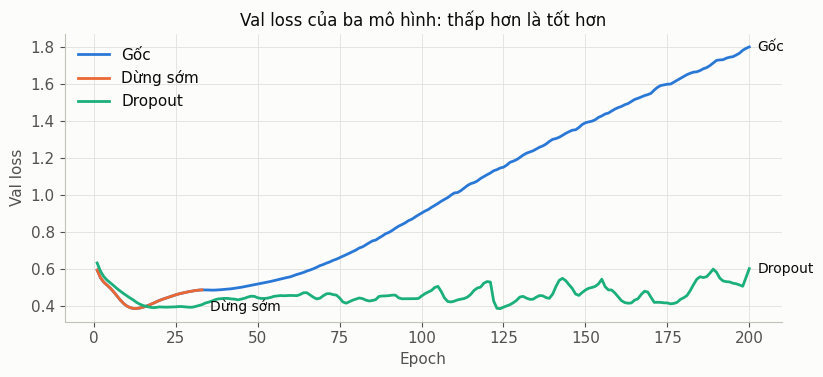

,Số epoch đã chạy,Val loss,Val accuracy
Cách làm,,,
Gốc,200,1.80,0.80
Dừng sớm,33,0.39,0.78
Dropout,200,0.60,0.82


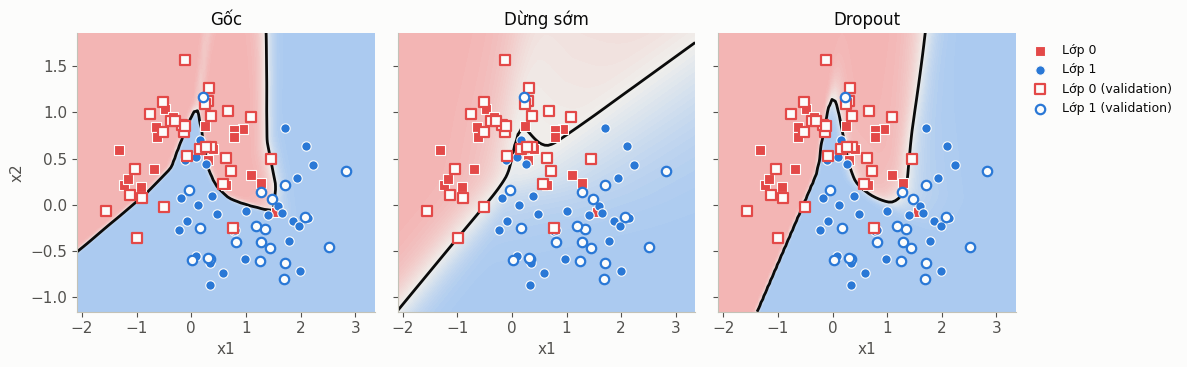

In [10]:
so_sanh_ba_cach(
    [("Gốc", mo_hinh_goc, lich_su),
     ("Dừng sớm", mo_hinh_dung_som, lich_su_dung_som),
     ("Dropout", mo_hinh_dropout, lich_su_dropout)],
    X_val, y_val, X_train, y_train,
)

### 📖 Đọc bảng cho đúng

Có thể bạn thấy **val accuracy** của ba mô hình khá gần nhau, thậm chí mô hình gốc còn nhỉnh hơn Dừng sớm một chút, trong khi **val loss** chênh lệch rất nhiều. Vì sao?

- **Accuracy** chỉ chấm đúng hay sai.
- **Loss** còn tính cả mức độ tự tin: đoán sai mà tự tin 99% bị phạt nặng hơn nhiều so với đoán sai khi chỉ tự tin 51%.

Mô hình gốc học vẹt nên **đoán sai mà vẫn rất tự tin**, vì thế loss cao. Tập validation ở đây chỉ có 50 điểm, nên 1 điểm đoán khác đi đã làm accuracy đổi 2%, đừng quá bận tâm với chênh lệch nhỏ đó.

### 💬 Giải thích bằng lời của bạn

Bấm đúp vào ô này và hoàn thành các câu:

> 1. Mô hình gốc học vẹt vì học quá khớp trên tập dữ liệu đã có nên phụ thuộc phần lớn vào đó để dự đoán
> 2. So với mô hình gốc, đường phân chia của Dropout có hình dạng tương tự nhưng khoảng chuyển màu rộng hơn giúp cho các điểm outlier không tác động quá nhiều đến mô hình, nên trên đề thi thử kết quả là tốt hơn
> 3. Nếu chỉ được chọn một cách cho bài này, tôi chọn early stopping vì mô hình hiện tại có quá ít dữ liệu để học, xác suất ngẫu nhiên là vẫn cao nên khoảng tin cậy không nên để quá hẹp. Dù acc của Dropout nhỉnh hơn nhưng nếu xét với các dữ liệu mới nhập vào thì điểm loss của chúng trên mô hình có Early Stopping sẽ là tốt hơn

<details><summary>💡 Bấm để xem gợi ý</summary>

- Hãy so hình dạng đường phân chia giữa ba hình, và cả **dải chuyển màu** quanh đường đen: dải rộng hơn nghĩa là mô hình bớt quá tự tin. Dropout có thể không làm đường đổi nhiều, nhưng val loss vẫn thấp hơn hẳn.
- Dropout tính loss train khi đang tắt bớt nơ-ron, nên đừng ngạc nhiên nếu loss train của nó cao hơn hoặc dao động nhiều hơn.
- Không có đáp án duy nhất cho câu 3. Dropout không phải lúc nào cũng giúp ích, nó cần thử với từng bài toán. Dừng sớm thì tiết kiệm thời gian chạy.
</details>

---
# 🎉 Tổng kết Bài 2

- Luôn vẽ **cả** train và validation, vì chỉ nhìn train thì không phát hiện được học vẹt
- Val loss bắt đầu đi lên là lúc quá khớp bắt đầu (slide 51)
- **Dừng sớm:** ngừng đúng lúc. **Dropout:** không cho mô hình dựa dẫm vào một vài nơ-ron

👉 **Bài tiếp theo:** tự tay chỉnh **tốc độ học** và **kích thước lô** để xem mô hình phản ứng ra sao.